# 💻 Análisis y Predicción de Precios de Laptops

**Proyecto final – Ciencia de Datos**
Equipo: Juan Bello · Martin · Jenncy — *Ingeniería de Sistemas*

**Pregunta guía:** ¿qué características de una laptop explican su precio, y podemos estimarlo a partir de sus especificaciones?

| Etapa | Contenido |
|---|---|
| 1 | Selección, exploración y limpieza de los datos |
| 2 | Estadística descriptiva, comparaciones y outliers |
| 3 | Visualizaciones, modelo de regresión lineal y conclusiones |

In [1]:
import os
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", "{:,.2f}".format)

---
# Etapa 1 · Fundamentos: selección, exploración y limpieza

## 1.1 El dataset y por qué lo elegimos

- **Fuente:** [Laptop Price – Kaggle](https://www.kaggle.com/datasets/muhammetvarl/laptop-price) (Muhammet Varlı). Especificaciones y precios de laptops de una tienda en línea (~2017-2018), con precios en **euros**.
- **Relación con nuestra carrera:** como ingenieros de sistemas solemos asesorar o decidir compras de equipos. Saber qué componentes encarecen una laptop permite evaluar cotizaciones y aprovechar mejor un presupuesto de TI.

In [2]:
# Si se ejecuta en Colab, el archivo se lee directamente desde GitHub
URL = "https://raw.githubusercontent.com/JEstebanBello/analisis-precios-laptops/main/datos/laptop_price.csv"
RUTA_LOCAL = "../datos/laptop_price.csv"
ruta = RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else URL

# El archivo no está en UTF-8: con la lectura por defecto falla, por eso usamos latin-1
df_original = pd.read_csv(ruta, encoding="latin-1")
print("Filas y columnas:", df_original.shape)
df_original.head()

Filas y columnas: (1303, 13)


,laptop_ID,Company,Product,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price_euros
0,1,Apple,MacBook Pro,Ultrabook,13.30,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,"1,339.69"
1,2,Apple,Macbook Air,Ultrabook,13.30,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,898.94
2,3,HP,250 G6,Notebook,15.60,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,8GB,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,575.00
3,4,Apple,MacBook Pro,Ultrabook,15.40,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,16GB,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,"2,537.45"
4,5,Apple,MacBook Pro,Ultrabook,13.30,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,8GB,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,"1,803.60"


## 1.2 Exploración: tipos de variables

In [3]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   laptop_ID         1303 non-null   int64  
 1   Company           1303 non-null   str    
 2   Product           1303 non-null   str    
 3   TypeName          1303 non-null   str    
 4   Inches            1303 non-null   float64
 5   ScreenResolution  1303 non-null   str    
 6   Cpu               1303 non-null   str    
 7   Ram               1303 non-null   str    
 8   Memory            1303 non-null   str    
 9   Gpu               1303 non-null   str    
 10  OpSys             1303 non-null   str    
 11  Weight            1303 non-null   str    
 12  Price_euros       1303 non-null   float64
dtypes: float64(2), int64(1), str(10)
memory usage: 132.5 KB


**Lectura:**
- **Numéricas:** solo `Inches` (pulgadas) y `Price_euros` (precio).
- **Categóricas:** `Company`, `TypeName`, `OpSys`, `Cpu`, `Gpu`, entre otras.
- ⚠️ `Ram` y `Weight` son números pero están guardados como **texto** (`"8GB"`, `"1.37kg"`), así que no se pueden promediar ni graficar todavía.

## 1.3 Problemas detectados

In [4]:
print("Valores nulos:", df_original.isna().sum().sum())
print("Duplicados exactos:", df_original.duplicated().sum())
print("Duplicados ignorando el ID:", df_original.drop(columns="laptop_ID").duplicated().sum())
print("\nSistemas operativos:", df_original["OpSys"].unique().tolist())

df_original[["Ram", "Weight", "Memory", "ScreenResolution", "Cpu"]].sample(5, random_state=1)

Valores nulos: 0
Duplicados exactos: 0
Duplicados ignorando el ID: 28

Sistemas operativos: ['macOS', 'No OS', 'Windows 10', 'Mac OS X', 'Linux', 'Android', 'Windows 10 S', 'Chrome OS', 'Windows 7']


,Ram,Weight,Memory,ScreenResolution,Cpu
644,4GB,2.4kg,500GB HDD,1366x768,Intel Core i3 6006U 2GHz
1275,8GB,1.2kg,512GB SSD,IPS Panel Full HD 1920x1080,Intel Core M 6Y30 0.9GHz
163,16GB,2.5kg,256GB SSD,IPS Panel Full HD 1920x1080,Intel Core i7 7700HQ 2.8GHz
1008,8GB,1.64kg,256GB SSD,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz
909,8GB,0.98kg,512GB SSD,IPS Panel Full HD / Touchscreen 1920x1080,Intel Core i7 7500U 2.7GHz


| Problema | Ejemplo | Solución |
|---|---|---|
| Codificación del archivo | falla al leer en UTF-8 | leer con `latin-1` |
| Duplicados ocultos | misma laptop con distinto `laptop_ID` | eliminar el ID y luego los duplicados |
| Números como texto | `"8GB"`, `"1.37kg"` | quitar la unidad y convertir a número |
| Varios datos en una columna | `"128GB SSD +  1TB HDD"` | separar en GB de SSD y GB de HDD |
| Texto con información útil | `"IPS Panel Touchscreen 1920x1080"` | extraer IPS, táctil y resolución |
| Categorías inconsistentes | `macOS` / `Mac OS X`, `Windows 10` / `Windows 10 S` | agrupar en categorías limpias |

No hay valores nulos: el reto de este dataset es el **formato**, no los datos faltantes.

## 1.4 Distribuciones iniciales

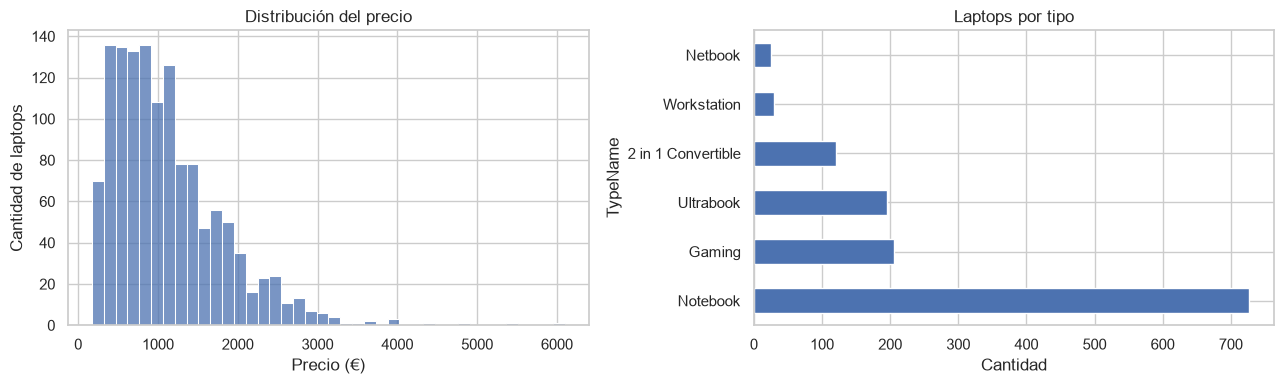

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_original["Price_euros"], bins=40, ax=ax[0])
ax[0].set(title="Distribución del precio", xlabel="Precio (€)", ylabel="Cantidad de laptops")
df_original["TypeName"].value_counts().plot.barh(ax=ax[1])
ax[1].set(title="Laptops por tipo", xlabel="Cantidad")
plt.tight_layout()
plt.show()

El precio tiene una **cola larga hacia la derecha**: la mayoría de laptops cuesta menos de 1.500 €, pero unas pocas superan los 3.000 €. Más de la mitad son de tipo *Notebook*.

## 1.5 Limpieza y transformación

In [6]:
df = df_original.drop(columns="laptop_ID").drop_duplicates().copy()
print("Filas eliminadas por duplicado:", len(df_original) - len(df))

# Quitar la unidad y convertir a número
df["Ram"] = df["Ram"].str.replace("GB", "").astype(int)
df["Weight"] = df["Weight"].str.replace("kg", "").astype(float)

Filas eliminadas por duplicado: 28


In [7]:
def separar_almacenamiento(texto):
    """'128GB SSD +  1TB HDD' -> SSD_GB=128, HDD_GB=1000. Flash cuenta como SSD; Hybrid como HDD."""
    ssd = hdd = 0
    for parte in texto.split("+"):
        cantidad, unidad = re.search(r"([\d.]+)(GB|TB)", parte).groups()
        gb = float(cantidad) * (1000 if unidad == "TB" else 1)
        if "SSD" in parte or "Flash" in parte:
            ssd += gb
        else:
            hdd += gb
    return pd.Series({"SSD_GB": ssd, "HDD_GB": hdd})

df[["SSD_GB", "HDD_GB"]] = df["Memory"].apply(separar_almacenamiento)
df[["Memory", "SSD_GB", "HDD_GB"]].drop_duplicates().head()

,Memory,SSD_GB,HDD_GB
0,128GB SSD,128.00,0.00
1,128GB Flash Storage,128.00,0.00
2,256GB SSD,256.00,0.00
3,512GB SSD,512.00,0.00
5,500GB HDD,0.00,500.00


In [8]:
# Pantalla: panel IPS, táctil y densidad de píxeles (PPI = nitidez de la pantalla)
resolucion = df["ScreenResolution"].str.extract(r"(\d+)x(\d+)").astype(int)
df["PPI"] = np.sqrt(resolucion[0] ** 2 + resolucion[1] ** 2) / df["Inches"]
df["IPS"] = df["ScreenResolution"].str.contains("IPS").astype(int)
df["Tactil"] = df["ScreenResolution"].str.contains("Touchscreen").astype(int)

In [9]:
def familia_cpu(cpu):
    for gama in ["i7", "i5", "i3"]:
        if f"Core {gama}" in cpu:
            return f"Intel {gama}"
    return "AMD" if cpu.startswith("AMD") else "Intel otro"

def sistema_operativo(so):
    if "Windows" in so:
        return "Windows"
    if "mac" in so.lower():
        return "macOS"
    return {"No OS": "Sin SO", "Linux": "Linux"}.get(so, "Otro")

df["CPU"] = df["Cpu"].apply(familia_cpu)
df["GPU"] = df["Gpu"].str.split().str[0]
df["SO"] = df["OpSys"].apply(sistema_operativo)

In [10]:
# Dataset final: columnas útiles con nombres en español
df = df.rename(columns={
    "Company": "Marca", "TypeName": "Tipo", "Inches": "Pulgadas",
    "Ram": "RAM_GB", "Weight": "Peso_kg", "Price_euros": "Precio_EUR",
})[["Marca", "Tipo", "CPU", "GPU", "SO", "Pulgadas", "RAM_GB", "SSD_GB",
    "HDD_GB", "Peso_kg", "PPI", "IPS", "Tactil", "Precio_EUR"]]

if os.path.isdir("../datos"):
    df.to_csv("../datos/laptops_limpio.csv", index=False)

df.head()

,Marca,Tipo,CPU,GPU,SO,Pulgadas,RAM_GB,SSD_GB,HDD_GB,Peso_kg,PPI,IPS,Tactil,Precio_EUR
0,Apple,Ultrabook,Intel i5,Intel,macOS,13.30,8,128.00,0.00,1.37,226.98,1,0,"1,339.69"
1,Apple,Ultrabook,Intel i5,Intel,macOS,13.30,8,128.00,0.00,1.34,127.68,0,0,898.94
2,HP,Notebook,Intel i5,Intel,Sin SO,15.60,8,256.00,0.00,1.86,141.21,0,0,575.00
3,Apple,Ultrabook,Intel i7,AMD,macOS,15.40,16,512.00,0.00,1.83,220.53,1,0,"2,537.45"
4,Apple,Ultrabook,Intel i5,Intel,macOS,13.30,8,256.00,0.00,1.37,226.98,1,0,"1,803.60"


## 1.6 Resumen del dataset depurado

In [11]:
resumen = pd.DataFrame({
    "Antes": [len(df_original), df_original.shape[1], df_original.select_dtypes("number").shape[1]],
    "Después": [len(df), df.shape[1], df.select_dtypes("number").shape[1]],
}, index=["Filas", "Columnas", "Columnas numéricas"])
resumen

,Antes,Después
Filas,1303,1275
Columnas,13,14
Columnas numéricas,3,9


Pasamos de **2 variables numéricas útiles a 9**, sin nulos ni duplicados. El dataset limpio queda guardado en `datos/laptops_limpio.csv`.

---
# Etapa 2 · Estadística descriptiva

## 2.1 Medidas de tendencia central

In [12]:
variables = ["Precio_EUR", "RAM_GB", "SSD_GB", "Peso_kg", "Pulgadas"]

tendencia = pd.DataFrame({
    "Media": df[variables].mean(),
    "Mediana": df[variables].median(),
    "Moda": df[variables].mode().iloc[0],
})
tendencia

,Media,Mediana,Moda
Precio_EUR,"1,134.97",989.00,"1,099.00"
RAM_GB,8.44,8.00,8.00
SSD_GB,190.47,256.00,256.00
Peso_kg,2.04,2.04,2.20
Pulgadas,15.02,15.60,15.60


**Interpretación:**
- **Precio:** la media (≈ 1.135 €) es mayor que la mediana (≈ 989 €). Unas pocas laptops muy caras "jalan" el promedio hacia arriba, así que **la mediana representa mejor el precio típico**.
- **RAM:** lo más común son **8 GB**; la media sube un poco por los equipos de 16-64 GB.
- **SSD:** la mediana y la moda son 256 GB, pero la media baja a ≈ 190 GB porque muchas laptops solo tienen disco duro (HDD), es decir, SSD = 0.
- **Pantalla:** el tamaño más común es **15,6"**, el estándar de los portátiles de oficina.

## 2.2 Medidas de dispersión

In [13]:
dispersion = pd.DataFrame({
    "Mínimo": df[variables].min(),
    "Máximo": df[variables].max(),
    "Rango": df[variables].max() - df[variables].min(),
    "Varianza": df[variables].var(),
    "Desv. estándar": df[variables].std(),
    "Coef. variación (%)": df[variables].std() / df[variables].mean() * 100,
})
dispersion

,Mínimo,Máximo,Rango,Varianza,Desv. estándar,Coef. variación (%)
Precio_EUR,174.00,"6,099.00","5,925.00","491,054.07",700.75,61.74
RAM_GB,2.00,64.00,62.00,25.99,5.10,60.39
SSD_GB,0.00,"1,024.00","1,024.00","34,046.46",184.52,96.88
Peso_kg,0.69,4.70,4.01,0.45,0.67,32.80
Pulgadas,10.10,18.40,8.30,2.04,1.43,9.52


**Interpretación:**
- El precio va de 174 € a 6.099 € (rango de 5.925 €) y su desviación estándar es ≈ 701 €: los precios están **muy dispersos**.
- La varianza está en unidades al cuadrado (€²), por eso es difícil de leer; la **desviación estándar** y el **coeficiente de variación** son más útiles para comparar.
- El **coeficiente de variación** permite comparar variables con unidades distintas: el SSD es la más variable (≈ 97 %), seguido del precio y la RAM (≈ 60 %), porque conviven equipos muy básicos y muy potentes. Las pulgadas son las más estables (≈ 10 %).

## 2.3 Comparación entre grupos

In [14]:
(df.groupby("Tipo")["Precio_EUR"]
   .agg(Cantidad="count", Media="mean", Mediana="median", Desv_estandar="std")
   .sort_values("Mediana", ascending=False))

,Cantidad,Media,Mediana,Desv_estandar
Tipo,,,,
Workstation,29,"2,280.36","2,064.90",712.64
Ultrabook,194,"1,556.68","1,499.00",484.74
Gaming,205,"1,731.38","1,492.80",814.17
2 in 1 Convertible,117,"1,289.71","1,199.00",617.44
Notebook,707,788.74,695.00,446.82
Netbook,23,673.38,355.00,592.09


In [15]:
comparacion = pd.DataFrame({
    "Mediana precio (€)": pd.concat([
        df.groupby("CPU")["Precio_EUR"].median(),
        df.groupby(np.where(df["SSD_GB"] > 0, "Con SSD", "Sin SSD"))["Precio_EUR"].median(),
    ])
}).sort_values("Mediana precio (€)", ascending=False)
comparacion

,Mediana precio (€)
Intel i7,"1,483.00"
Con SSD,"1,199.00"
Intel i5,955.00
Sin SSD,599.00
Intel i3,499.00
AMD,469.00
Intel otro,349.00


**Interpretación:**
- Las **Workstation** son las más caras (mediana ≈ 2.065 €), seguidas de **Ultrabook** y **Gaming** (≈ 1.500 €); las **Netbook** son las más baratas (≈ 355 €).
- Un **Intel i7** (≈ 1.483 €) cuesta casi el triple que un **i3** (≈ 499 €).
- Las laptops **con SSD** cuestan el doble que las que solo tienen disco duro (≈ 1.199 € vs. 599 €).

## 2.4 Outliers (valores atípicos)

In [16]:
q1, q3 = df["Precio_EUR"].quantile([0.25, 0.75])
limite_superior = q3 + 1.5 * (q3 - q1)
outliers = df[df["Precio_EUR"] > limite_superior]

print(f"Límite superior (método IQR): {limite_superior:,.0f} €")
print(f"Laptops atípicas: {len(outliers)} ({len(outliers) / len(df):.1%})")
outliers["Tipo"].value_counts()

Límite superior (método IQR): 2,828 €
Laptops atípicas: 28 (2.2%)


Tipo
Gaming         17
Workstation     6
Notebook        3
Ultrabook       2
Name: count, dtype: int64

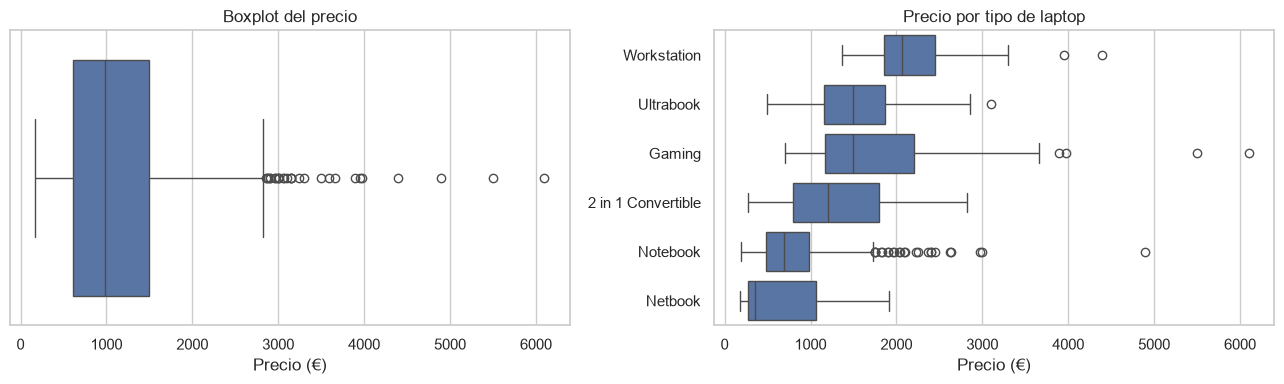

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x=df["Precio_EUR"], ax=ax[0])
ax[0].set(title="Boxplot del precio", xlabel="Precio (€)")
sns.boxplot(data=df, x="Precio_EUR", y="Tipo", ax=ax[1],
            order=df.groupby("Tipo")["Precio_EUR"].median().sort_values(ascending=False).index)
ax[1].set(title="Precio por tipo de laptop", xlabel="Precio (€)", ylabel="")
plt.tight_layout()
plt.show()

**Decisión:** 28 laptops (2,2 %) superan los 2.828 €; casi todas son *Gaming* (17) o *Workstation* (6). Son laptops **reales** (gaming y workstations de gama alta), no errores de captura. **Los conservamos**, porque eliminarlos borraría justamente el segmento más caro del mercado.

## 2.5 Relaciones entre variables

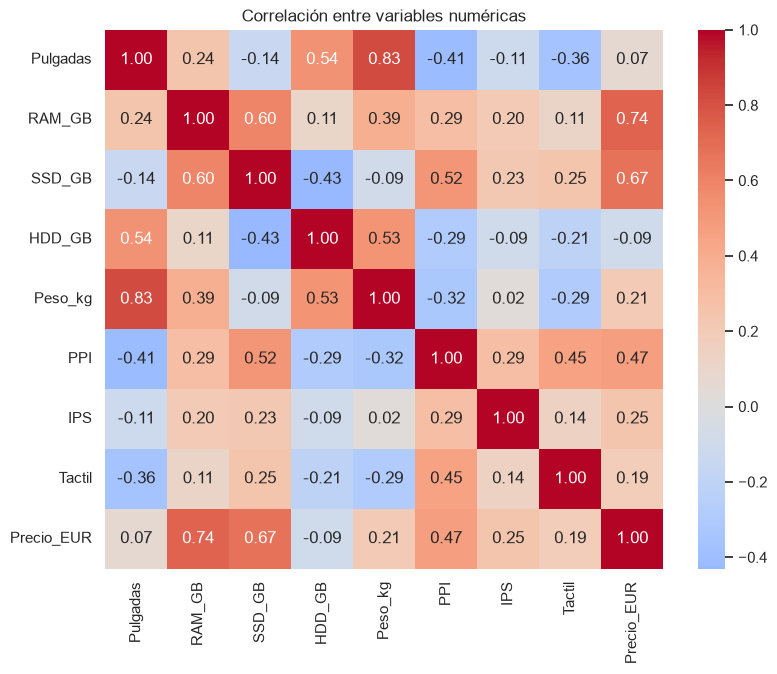

In [18]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables numéricas")
plt.show()

**Hipótesis a partir de los datos:**
1. **La RAM es el factor que más se relaciona con el precio** (correlación ≈ 0,74).
2. **El SSD también encarece el equipo** (≈ 0,67), mientras que el HDD casi no influye.
3. **Una pantalla más nítida (PPI) se asocia con precios más altos** (≈ 0,47).
4. El tamaño de pantalla casi no influye en el precio.

Estas hipótesis guían la Etapa 3.

---
# Etapa 3 · Visualización, modelo y storytelling

## 3.1 La historia en gráficos

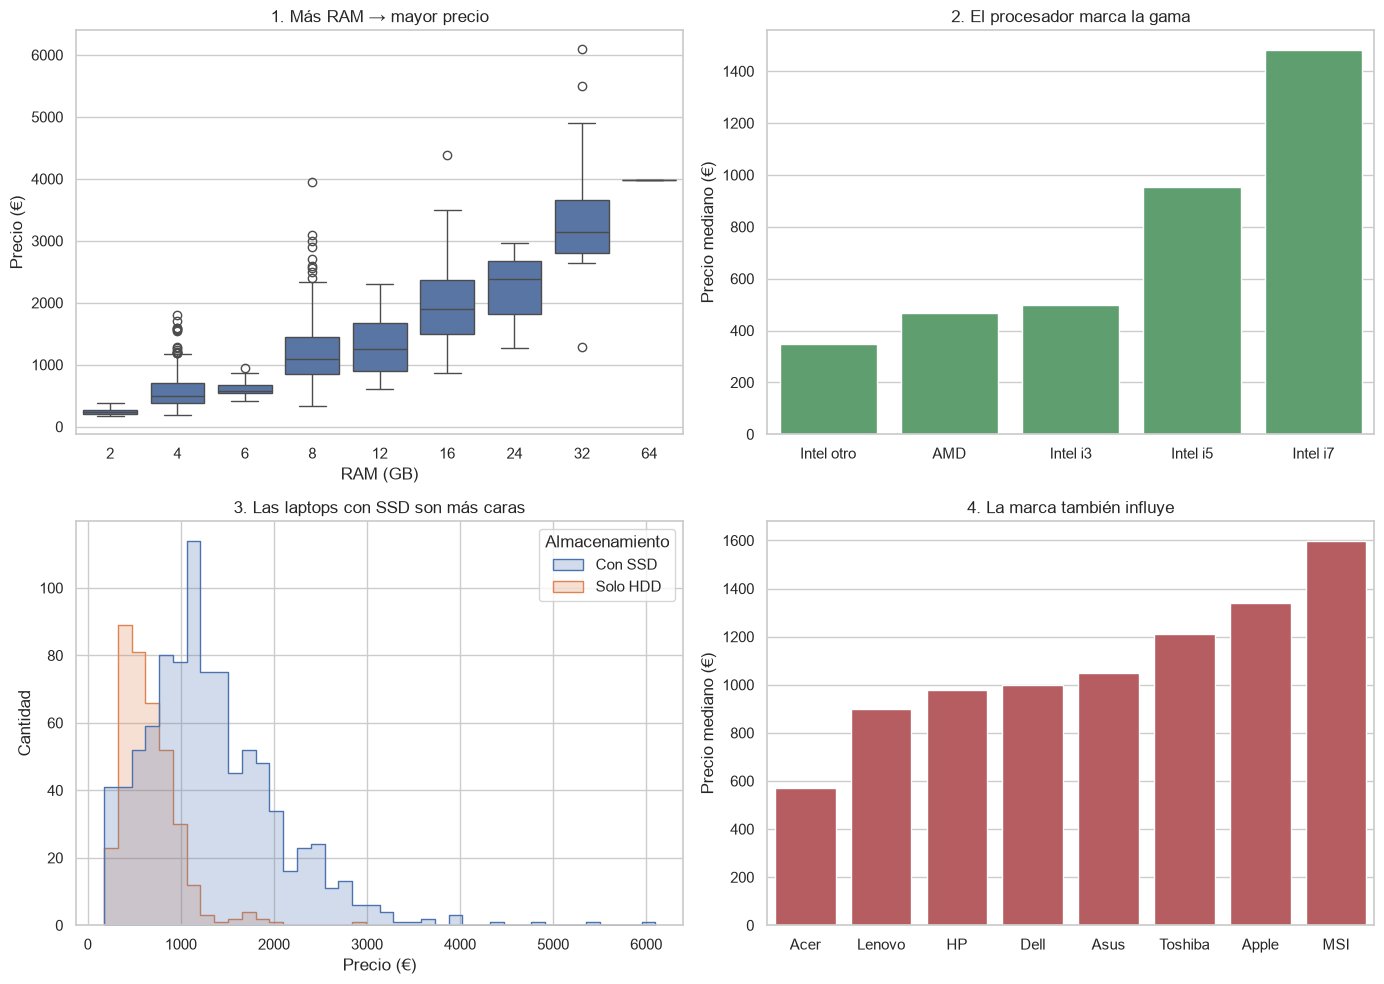

In [19]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# 1. RAM vs precio
sns.boxplot(data=df, x="RAM_GB", y="Precio_EUR", ax=ax[0, 0], color="#4C72B0")
ax[0, 0].set(title="1. Más RAM → mayor precio", xlabel="RAM (GB)", ylabel="Precio (€)")

# 2. Familia de CPU
orden_cpu = df.groupby("CPU")["Precio_EUR"].median().sort_values().index
sns.barplot(data=df, x="CPU", y="Precio_EUR", estimator="median", errorbar=None,
            order=orden_cpu, ax=ax[0, 1], color="#55A868")
ax[0, 1].set(title="2. El procesador marca la gama", xlabel="", ylabel="Precio mediano (€)")

# 3. SSD vs solo HDD
df_ssd = df.assign(Almacenamiento=np.where(df["SSD_GB"] > 0, "Con SSD", "Solo HDD"))
sns.histplot(data=df_ssd, x="Precio_EUR", hue="Almacenamiento", bins=40,
             element="step", ax=ax[1, 0])
ax[1, 0].set(title="3. Las laptops con SSD son más caras", xlabel="Precio (€)", ylabel="Cantidad")

# 4. Marcas principales
top_marcas = df["Marca"].value_counts().head(8).index
orden_marca = df[df["Marca"].isin(top_marcas)].groupby("Marca")["Precio_EUR"].median().sort_values().index
sns.barplot(data=df[df["Marca"].isin(top_marcas)], x="Marca", y="Precio_EUR", estimator="median",
            errorbar=None, order=orden_marca, ax=ax[1, 1], color="#C44E52")
ax[1, 1].set(title="4. La marca también influye", xlabel="", ylabel="Precio mediano (€)")

plt.tight_layout()
plt.show()

**Lo que cuentan los gráficos:**
1. Cada salto de RAM sube claramente el precio típico: 4 GB ≈ 498 €, 8 GB ≈ 1.099 €, 16 GB ≈ 1.895 €.
2. Pasar de i3 a i7 casi triplica el precio mediano: el procesador define la gama del equipo.
3. Las laptops que solo tienen HDD se concentran en la zona barata; las de SSD se reparten hacia precios altos.
4. **MSI** (≈ 1.599 €) y **Apple** (≈ 1.340 €) tienen los precios medianos más altos; **Acer** (≈ 572 €) es la más económica.

## 3.2 Modelo predictivo: regresión lineal

**¿Qué hace?** Busca la recta (en varias dimensiones) que mejor estima el precio a partir de las especificaciones:

$$\text{Precio} = b_0 + b_1\cdot\text{RAM} + b_2\cdot\text{SSD} + b_3\cdot\text{Peso} + b_4\cdot\text{PPI}$$

Usamos las 4 variables más relacionadas con el precio. Entrenamos con el **80 %** de los datos y evaluamos con el **20 %** restante, que el modelo nunca vio.

In [20]:
X = df[["RAM_GB", "SSD_GB", "Peso_kg", "PPI"]]
y = df["Precio_EUR"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
modelo = LinearRegression().fit(X_train, y_train)
y_pred = modelo.predict(X_test)

print(f"R²:  {r2_score(y_test, y_pred):.2f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):,.0f} €")

R²:  0.70
MAE: 298 €


In [21]:
coeficientes = pd.DataFrame({"Efecto en el precio (€)": modelo.coef_},
                            index=["+1 GB de RAM", "+1 GB de SSD", "+1 kg de peso", "+1 punto de PPI"])
coeficientes

,Efecto en el precio (€)
+1 GB de RAM,58.28
+1 GB de SSD,1.11
+1 kg de peso,152.36
+1 punto de PPI,3.84


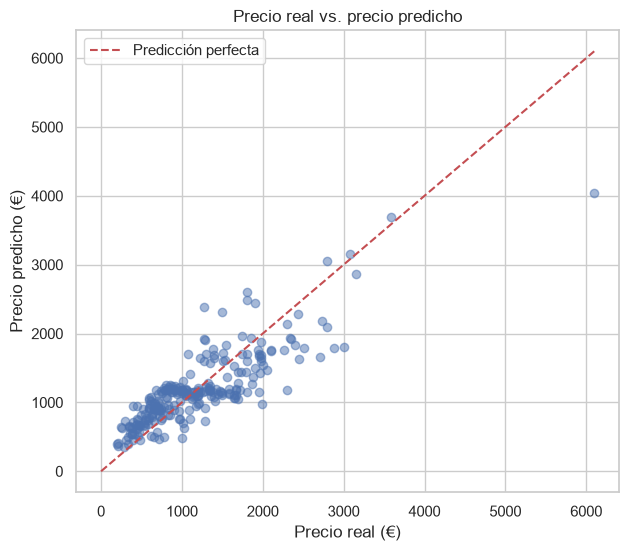

In [22]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
limites = [0, max(y_test.max(), y_pred.max())]
plt.plot(limites, limites, "r--", label="Predicción perfecta")
plt.xlabel("Precio real (€)")
plt.ylabel("Precio predicho (€)")
plt.title("Precio real vs. precio predicho")
plt.legend()
plt.show()

**Interpretación del modelo:**
- **R² ≈ 0,70:** el modelo explica cerca del 70 % de las diferencias de precio entre laptops usando solo 4 especificaciones.
- **MAE ≈ 298 €:** en promedio, la predicción se equivoca por ese monto.
- **Coeficientes:** cada GB adicional de RAM suma ≈ 58 € y cada 100 GB de SSD ≈ 111 €, manteniendo lo demás igual.
- El peso tiene efecto positivo porque las laptops pesadas suelen ser *gaming* o *workstation*, que son caras.
- **Ejemplo (celda siguiente):** una laptop con 16 GB de RAM, 512 GB de SSD, 1,8 kg y pantalla Full HD de 15,6" debería costar ≈ 1.870 €.
- **Limitaciones:** el modelo falla más en las laptops muy caras (puntos alejados de la línea roja) y no considera la marca ni la GPU. Además, los precios son de 2017-2018 y están en euros.

In [23]:
# Ejemplo práctico: ¿cuánto debería costar esta laptop?
laptop_nueva = pd.DataFrame({"RAM_GB": [16], "SSD_GB": [512], "Peso_kg": [1.8], "PPI": [141]})
print(f"Precio estimado: {modelo.predict(laptop_nueva)[0]:,.0f} €")

Precio estimado: 1,872 €


---
## 3.3 Conclusiones

1. **Limpiar fue la mitad del trabajo:** el dataset no tenía nulos, pero sí números guardados como texto, columnas combinadas, duplicados ocultos y categorías inconsistentes.
2. **El precio típico de una laptop es ≈ 989 €**, con mucha dispersión y algunos equipos de gama alta muy por encima.
3. **RAM, SSD y procesador son lo que más encarece una laptop.** El disco duro (HDD) y el tamaño de pantalla casi no influyen.
4. **Una regresión lineal con solo 4 variables explica ~70 % del precio**, suficiente para tener una referencia rápida.

## 3.4 Aplicación profesional

Como ingenieros de sistemas, este análisis sirve en el **área de TI de una empresa** para:
- **Validar cotizaciones:** si un proveedor ofrece una laptop muy por encima del precio estimado, hay argumentos para negociar.
- **Optimizar el presupuesto:** priorizar RAM y SSD, que es lo que más aporta, antes que pagar por una pantalla más grande.
- **Definir perfiles de equipos** (básico, desarrollo, diseño) con un costo estimado para cada uno.

El mismo flujo —**datos → limpieza → estadística → visualización → modelo → decisión**— se puede aplicar a inventarios de equipos, consumo de servidores o tiempos de respuesta de sistemas.